To run in Google colab, create a new folder in files and name it *data*. Then, upload *pitchfork_discogs.csv* into it.

In [171]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import umap
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

In [172]:
pitch_disogs = "/content/data/pitchfork_discogs.csv"
review_df = df=pd.read_csv(pitch_disogs)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

# Overall Dataset

In [173]:
review_df['reviewdate'] = pd.to_datetime(review_df['reviewdate'])

In [174]:
review_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10764 entries, 0 to 10763
Data columns (total 32 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   artist            10764 non-null  object        
 1   album             10764 non-null  object        
 2   reviewauthor      10764 non-null  object        
 3   score             10764 non-null  float64       
 4   releaseyear       10764 non-null  float64       
 5   reviewdate        10764 non-null  datetime64[ns]
 6   recordlabel       10756 non-null  object        
 7   genre             10764 non-null  object        
 8   danceability      10764 non-null  float64       
 9   energy            10764 non-null  float64       
 10  key               10764 non-null  float64       
 11  loudness          10764 non-null  float64       
 12  speechiness       10764 non-null  float64       
 13  acousticness      10764 non-null  float64       
 14  instrumentalness  1076

In [175]:
cols = [
    'releaseyear',
    'score',
    'rating_avg',
    'rating_count',
    'danceability',
    'energy',
    'key',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]
review_df[cols].describe().round(3)

,releaseyear,score,rating_avg,rating_count,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000
mean,2010.160,7.029,4.174,75.061,0.502,0.607,5.221,-9.277,0.087,0.297,0.300,0.193,0.396,120.527
std,5.317,1.252,0.313,184.586,0.156,0.204,1.595,4.313,0.083,0.261,0.305,0.092,0.181,15.327
min,1998.000,0.000,1.500,10.000,0.060,0.000,0.000,-51.729,0.011,0.000,0.000,0.021,0.000,24.708
25%,2006.000,6.500,4.000,18.000,0.399,0.476,4.350,-11.208,0.041,0.087,0.019,0.134,0.258,111.423
50%,2010.000,7.300,4.200,34.000,0.503,0.631,5.250,-8.427,0.056,0.221,0.181,0.174,0.394,120.481
75%,2015.000,7.800,4.390,73.000,0.612,0.759,6.111,-6.327,0.094,0.457,0.559,0.227,0.524,129.237
max,2019.000,10.000,5.000,9667.000,0.974,0.998,11.000,1.984,0.950,0.995,0.982,0.978,0.969,199.958


## EDA Pitchfork Scores

### Overall Pitchfork Score statistics

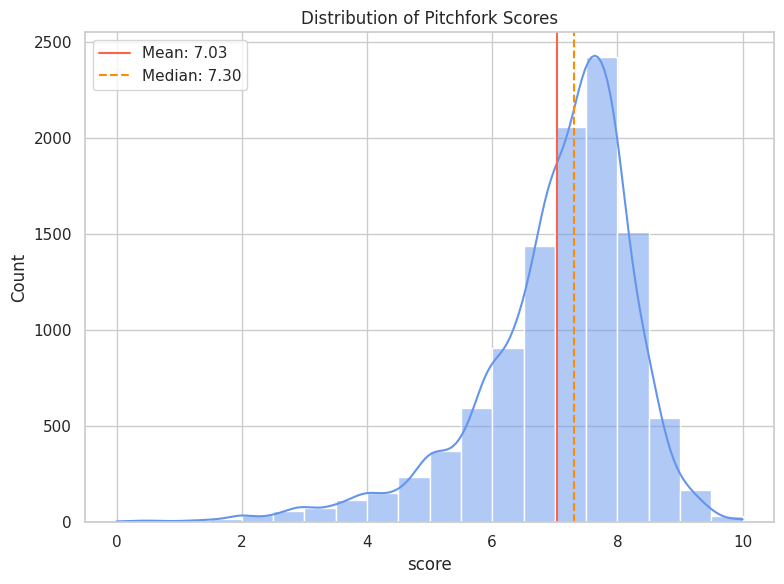

In [176]:
score = review_df['score']

plt.figure(figsize=(8, 6))

sns.histplot(score, bins=20, kde=True, color = 'cornflowerblue')
plt.axvline(score.mean(),
                color = 'tomato',
                linestyle = '-',
                label = f'Mean: {score.mean():.2f}')
plt.axvline(score.median(),
                color = 'darkorange',
                linestyle = '--',
                label = f'Median: {score.median():.2f}')
plt.title('Distribution of Pitchfork Scores')
plt.legend()

plt.tight_layout()
plt.show()

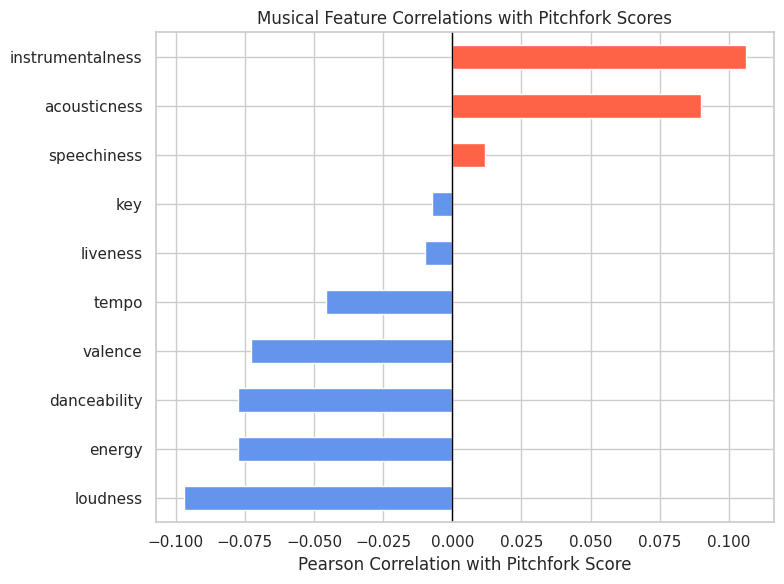

Feature correlations with Pitchfork Score:
loudness           -0.097
energy             -0.077
danceability       -0.077
valence            -0.073
tempo              -0.046
liveness           -0.010
key                -0.007
speechiness         0.012
acousticness        0.090
instrumentalness    0.106
Name: score, dtype: float64


In [177]:
cols = [
    'score',
    'genre',
    'reviewauthor',
    'releaseyear',
    'reviewdate',
    'danceability',
    'energy',
    'key',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

pitchfork_df = review_df[cols].copy()

score_correlations = (
    pitchfork_df.corr(numeric_only=True)['score']
    .drop(['score', 'releaseyear'])
    .sort_values()
)

plt.figure(figsize=(8, 6))

colors = [
    'cornflowerblue' if value < 0 else 'tomato'
    for value in score_correlations
]

score_correlations.plot(
    kind="barh",
    color=colors
)

plt.axvline(0, color = 'black', linewidth = 1)
plt.xlabel('Pearson Correlation with Pitchfork Score')
plt.title('Musical Feature Correlations with Pitchfork Scores')
plt.tight_layout()
plt.show()

print('Feature correlations with Pitchfork Score:')
print(score_correlations.round(3))

### Groupby Genre

In [178]:
genre_summary = (
    pitchfork_df.groupby('genre')['score']
    .agg(['mean', 'std', 'min', 'median', 'max', 'count'])
    .round(3)
    .sort_values("mean", ascending=False)
)

In [179]:
genre_summary

,mean,std,min,median,max,count
genre,,,,,,
Jazz,7.409,1.117,3.0,7.6,10.0,144
Experimental,7.402,1.058,0.3,7.6,10.0,987
Global,7.336,1.041,2.2,7.6,9.0,81
Folk/Country,7.290,1.048,2.3,7.5,10.0,403
Metal,7.101,1.196,0.8,7.4,9.0,569
Rap,7.053,1.298,1.6,7.3,10.0,674
Pop/R&B,7.019,1.108,2.0,7.2,10.0,653
Unknown,6.989,1.122,0.4,7.2,9.7,627
Rock,6.951,1.315,0.0,7.2,10.0,4042


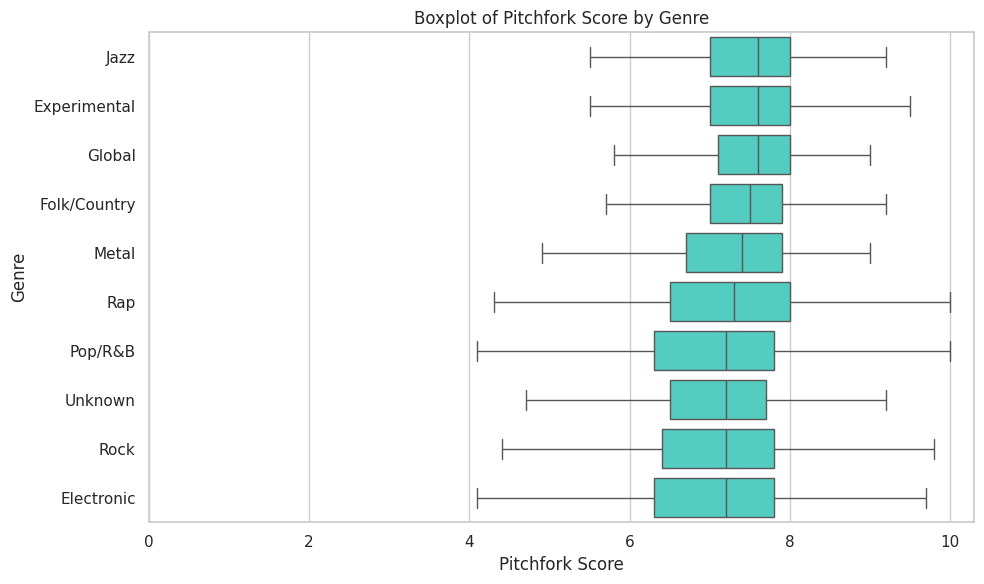

In [180]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data = pitchfork_df,
    x = 'score',
    y = 'genre',
    order = genre_summary.sort_values("median", ascending=False).index,
    color = 'turquoise',
    showfliers = False
)
plt.xlim(left = 0)
plt.title('Boxplot of Pitchfork Score by Genre')
plt.xlabel('Pitchfork Score')
plt.ylabel('Genre')

plt.tight_layout()
plt.show()

### Groupby Review Date

In [181]:
(pitchfork_df['reviewdate'].dt.year - pitchfork_df['releaseyear'] > 1).sum()

np.int64(13)

In [182]:
rdate_summary = (
    pitchfork_df.groupby(pitchfork_df['reviewdate'].dt.year)['score']
    .agg(['mean', 'std', 'min', 'median', 'max', 'count'])
    .round(3)
    .sort_index()
)

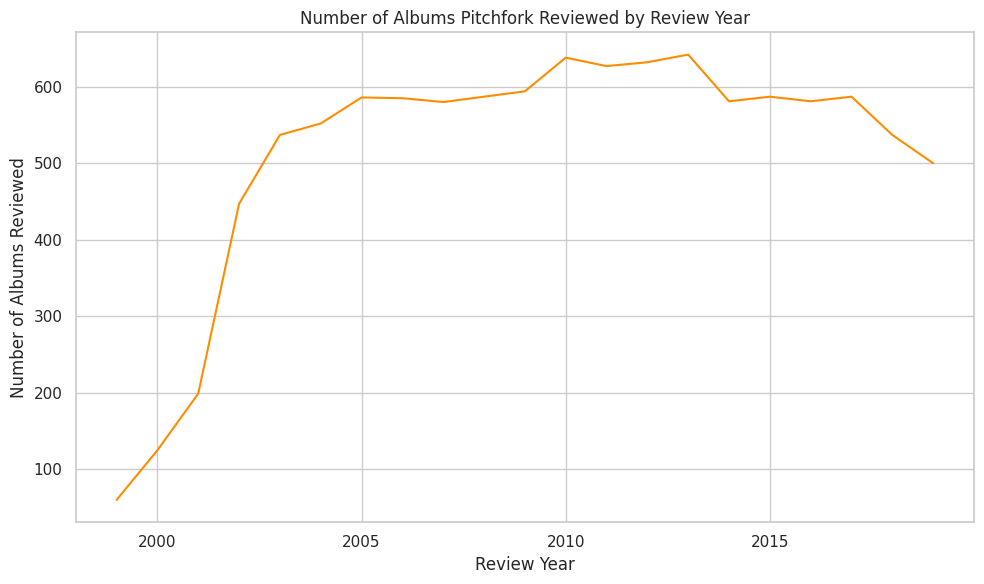

In [183]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data = rdate_summary,
    x = 'reviewdate',
    y = 'count',
    color = 'darkorange'
)
plt.xlim(left = 1998)
plt.xticks(range(2000, 2020, 5))
plt.title('Number of Albums Pitchfork Reviewed by Review Year')
plt.xlabel('Review Year')
plt.ylabel('Number of Albums Reviewed')

plt.tight_layout()
plt.show()

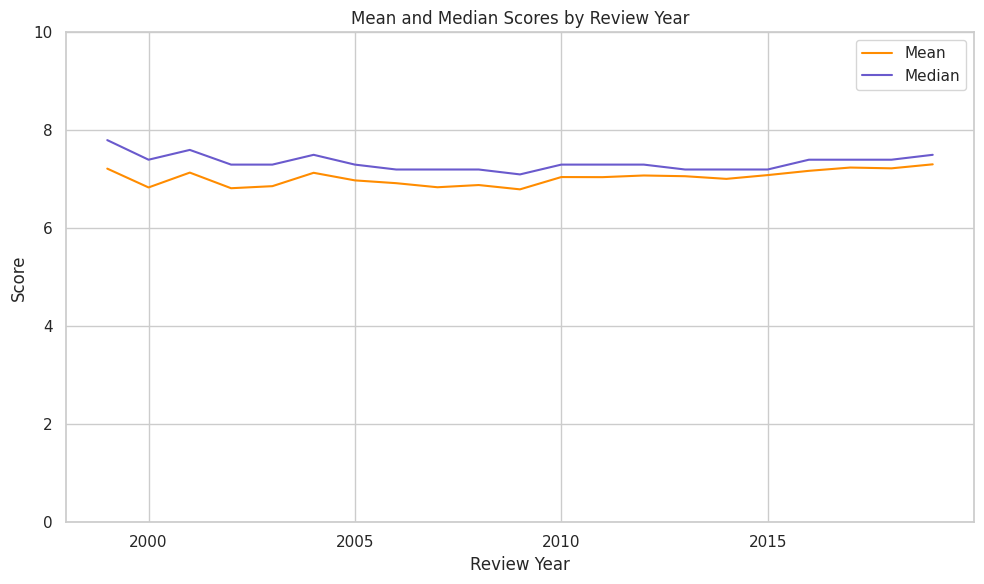

In [184]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data = rdate_summary,
    x = 'reviewdate',
    y = 'mean',
    color = 'darkorange',
    label='Mean'
)
sns.lineplot(
    data = rdate_summary,
    x = 'reviewdate',
    y = 'median',
    color = 'slateblue',
    label='Median'
)
plt.xlim(left = 1998)
plt.xticks(range(2000, 2020, 5))
plt.ylim(0, 10)
plt.title('Mean and Median Scores by Review Year')
plt.xlabel('Review Year')
plt.ylabel('Score')

plt.tight_layout()
plt.show()

In [185]:
bins = [1999, 2005, 2010, 2015, 2020]
labels = ['1999-2004', '2005-2009', '2010-2014', '2015-2019']

pitchfork_df['years_bin'] = pd.cut(
    pitchfork_df['reviewdate'].dt.year,
    bins = bins,
    labels = labels,
    right = False
)

In [186]:
rdate_bin_summary = (
    pitchfork_df.groupby('years_bin', observed=True)['score']
    .agg(['mean', 'std', 'min', 'median', 'max', 'count'])
    .round(3)
    .sort_index()
)

In [187]:
rdate_bin_summary

,mean,std,min,median,max,count
years_bin,,,,,,
1999-2004,6.967,1.616,0.0,7.4,10.0,1920
2005-2009,6.883,1.371,0.0,7.2,10.0,2932
2010-2014,7.049,1.093,1.0,7.3,10.0,3120
2015-2019,7.202,0.940,1.6,7.4,10.0,2792


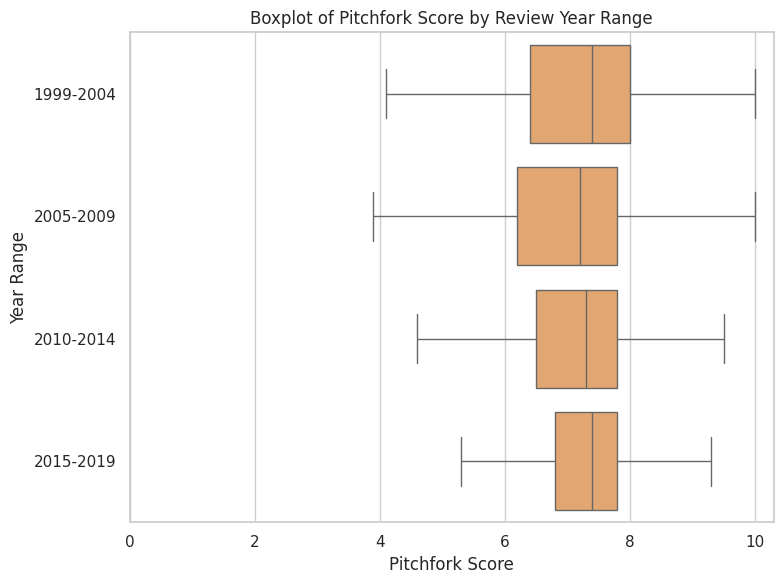

In [188]:
plt.figure(figsize=(8, 6))
sns.boxplot(
    data = pitchfork_df,
    x = 'score',
    y = 'years_bin',
    order = rdate_bin_summary.index,
    color = 'sandybrown',
    orient ='h',
    showfliers = False
)
plt.xlim(left = 0)
plt.title('Boxplot of Pitchfork Score by Review Year Range')
plt.xlabel('Pitchfork Score')
plt.ylabel('Year Range')
plt.tight_layout()
plt.show()

### Groupby Reviewer

In [189]:
reviewer_summary = (
    pitchfork_df.groupby('reviewauthor')['score']
    .agg(['mean', 'std', 'min', 'median', 'max', 'count'])
    .round(3)
    .sort_values('count', ascending = False)
)

reviewer_summary.head(15).round(3)

,mean,std,min,median,max,count
reviewauthor,,,,,,
Ian Cohen,6.482,1.488,0.2,6.6,9.3,462
Stephen M. Deusner,6.796,1.351,2.1,7.2,9.6,333
Joe Tangari,7.317,0.846,3.5,7.5,8.9,331
Mark Richardson,7.562,1.190,2.5,7.8,10.0,324
Stuart Berman,7.110,0.966,1.0,7.3,9.2,324
Brian Howe,7.121,0.895,2.8,7.4,9.0,260
Philip Sherburne,7.476,0.734,4.0,7.6,9.1,245
Marc Hogan,6.583,1.537,1.2,6.8,9.2,236
Nate Patrin,7.048,1.149,2.8,7.3,9.2,197


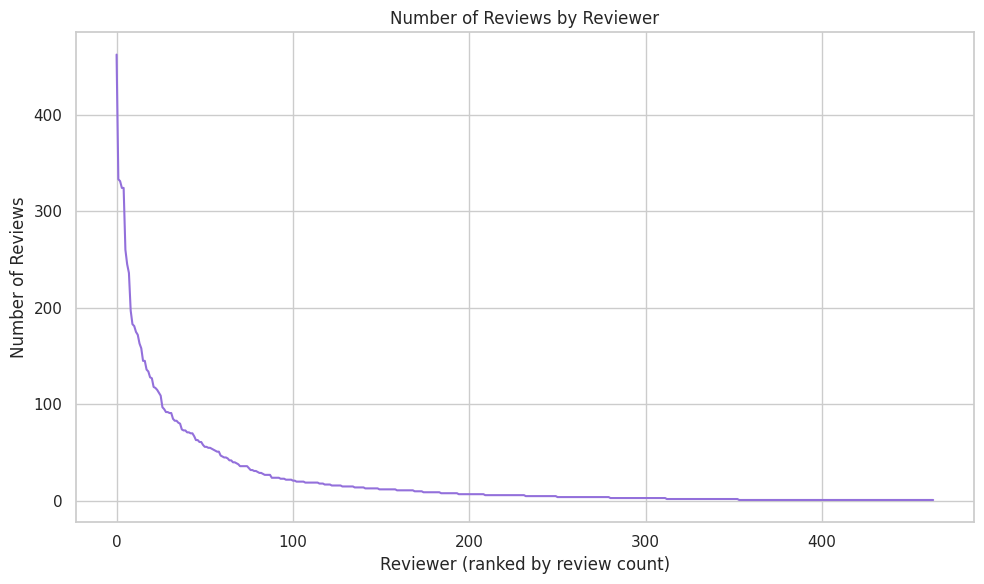

In [190]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data = reviewer_summary,
    x = range(len(reviewer_summary)),
    y = "count",
    color = "mediumpurple"
)

plt.title('Number of Reviews by Reviewer')
plt.xlabel('Reviewer (ranked by review count)')
plt.ylabel('Number of Reviews')

plt.tight_layout()
plt.show()

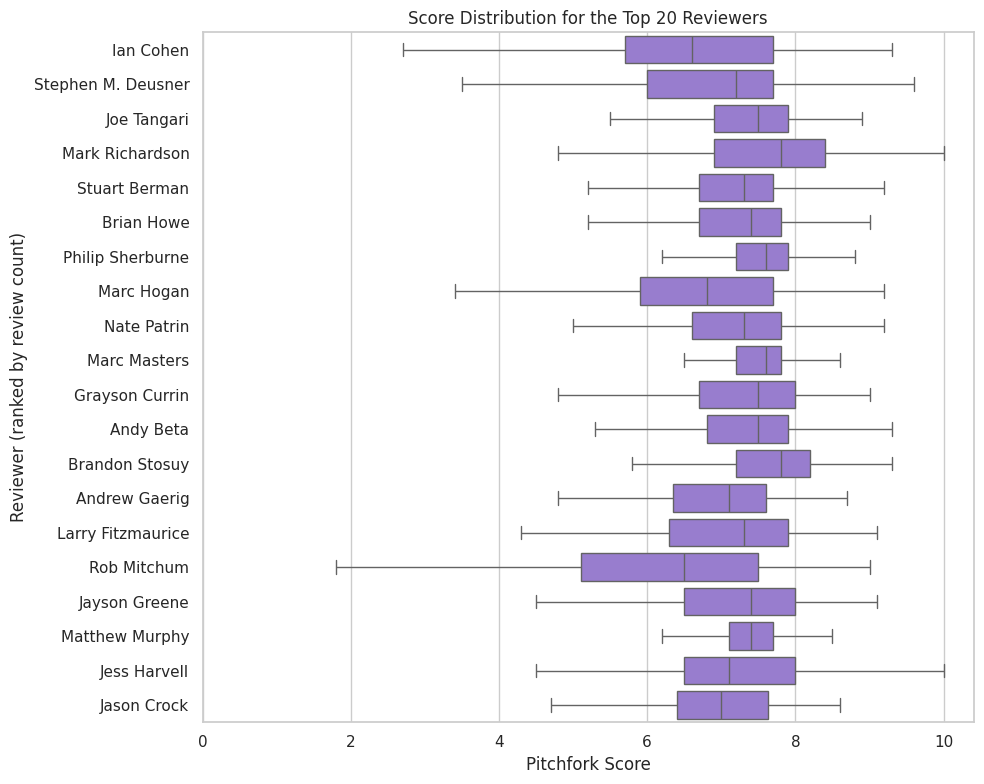

In [191]:
top20_reviewers = reviewer_summary.head(20).index

top20_df = review_df[
    review_df['reviewauthor'].isin(top20_reviewers)
]

plt.figure(figsize=(10, 8))
sns.boxplot(
    data = top20_df,
    x = 'score',
    y = 'reviewauthor',
    order = top20_reviewers,
    color = 'mediumpurple',
    orient = 'h',
    showfliers = False
)
plt.xlim(left = 0)
plt.title('Score Distribution for the Top 20 Reviewers')
plt.xlabel('Pitchfork Score')
plt.ylabel('Reviewer (ranked by review count)')

plt.tight_layout()
plt.show()

## EDA Discogs Ratings

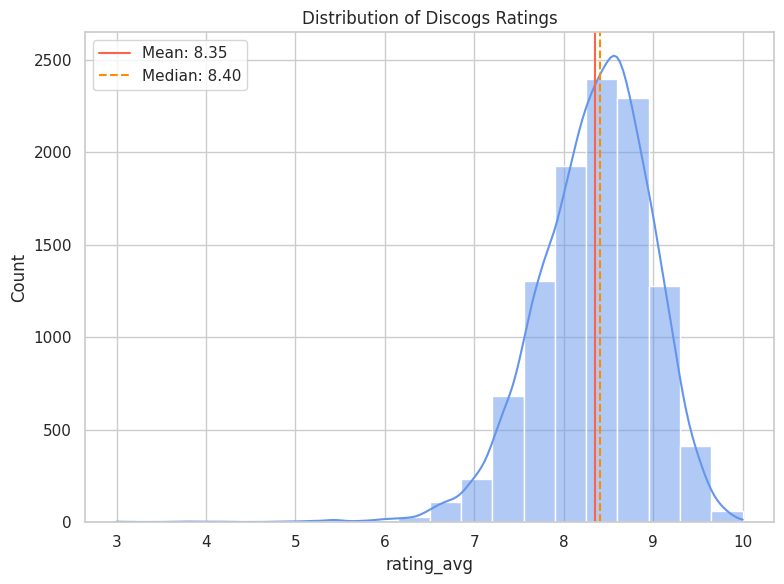

In [192]:
rating = review_df['rating_avg'] * 2

plt.figure(figsize=(8, 6))

sns.histplot(rating, bins=20, kde=True, color = 'cornflowerblue')
plt.axvline(rating.mean(),
                color = 'tomato',
                linestyle = '-',
                label = f'Mean: {rating.mean():.2f}')
plt.axvline(rating.median(),
                color = 'darkorange',
                linestyle = '--',
                label = f'Median: {rating.median():.2f}')
plt.title('Distribution of Discogs Ratings')
plt.legend()

plt.tight_layout()
plt.show()

In [193]:
cols = [
    'rating_avg',
    'rating_count',
    'genre',
    'releaseyear',
    'danceability',
    'energy',
    'key',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

discogs_df = review_df[cols].copy()

### Bin by Rating_count

In [194]:
discogs_df['rating_count'].max()

9667.0

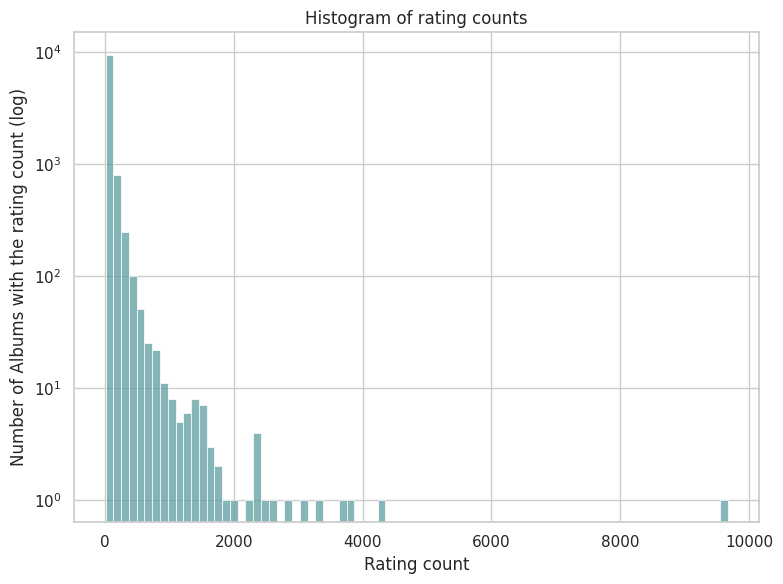

In [195]:
plt.figure(figsize=(8, 6))
sns.histplot(discogs_df["rating_count"], bins = 80, color = 'cadetblue')
plt.yscale("log")
plt.xlabel("Rating count")
plt.ylabel("Number of Albums with the rating count (log)")
plt.title("Histogram of rating counts")

plt.tight_layout()
plt.show()

In [196]:
discogs_df["counts_bin"], bins = pd.qcut(discogs_df["rating_count"], 5, labels=False, retbins = True)
bins

array([  10. ,   16. ,   26.2,   45. ,   88. , 9667. ])

In [197]:
bins_summary = (
    discogs_df.groupby('counts_bin')['rating_avg']
    .agg(['mean', 'std', 'min', 'median', 'max', 'count'])
    .round(3)
    .sort_values('counts_bin', ascending = True)
)

bins_summary.round(3)

,mean,std,min,median,max,count
counts_bin,,,,,,
0,4.093,0.376,1.50,4.10,5.00,2207
1,4.146,0.315,2.41,4.17,5.00,2099
2,4.169,0.300,2.06,4.19,4.93,2182
3,4.201,0.271,3.10,4.22,4.91,2129
4,4.264,0.261,3.00,4.30,4.89,2147


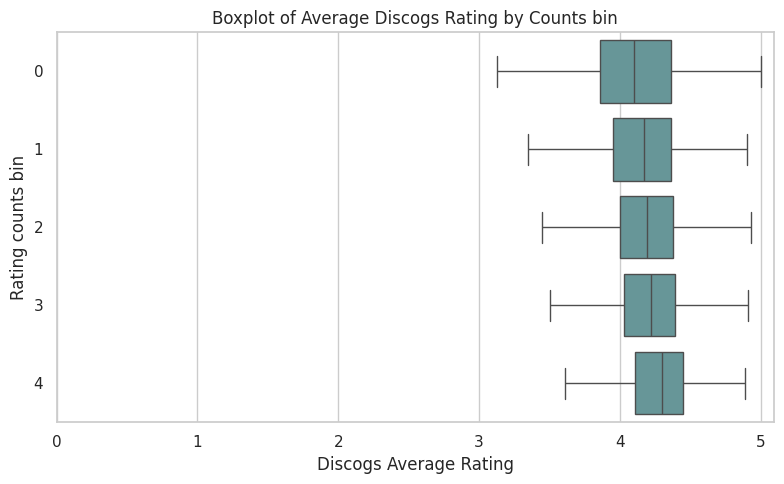

In [198]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data = discogs_df,
    x = 'rating_avg',
    y = 'counts_bin',
    order = bins_summary.index,
    color = 'cadetblue',
    orient = 'h',
    showfliers = False
)
plt.xlim(left = 0)
plt.title('Boxplot of Average Discogs Rating by Counts bin')
plt.xlabel('Discogs Average Rating')
plt.ylabel('Rating counts bin')
plt.tight_layout()
plt.show()

## Musicality UMAP

In [199]:
top_5_genre = review_df['genre'].value_counts().head(5).index

review_filtered = review_df[review_df['genre'].isin(top_5_genre)]

In [200]:
reducer = umap.UMAP(random_state = 424)

review_data = review_filtered[
    [
    "danceability", "energy", "key", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence", "tempo"
    ]
].values

scaled_review_data = StandardScaler().fit_transform(review_data)

In [201]:
embedding = reducer.fit_transform(scaled_review_data)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


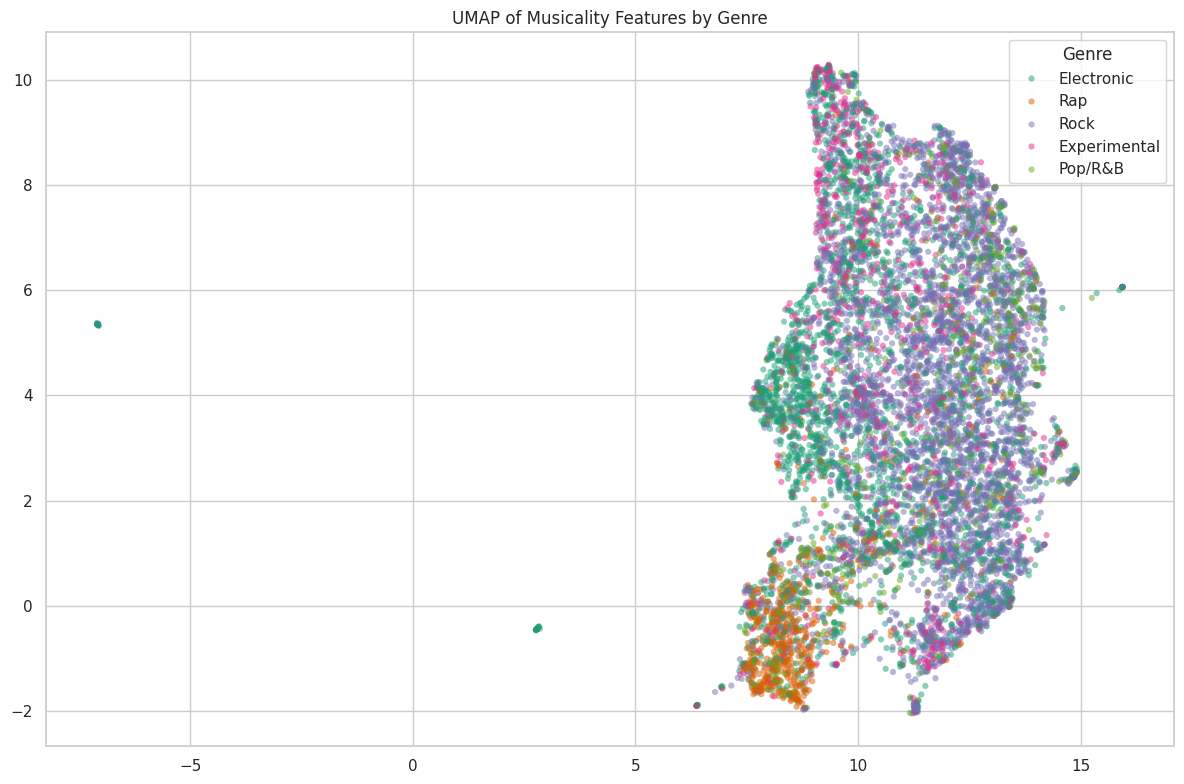

In [202]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x = embedding[:, 0],
    y = embedding[:, 1],
    hue = review_filtered['genre'],
    alpha = 0.5,
    s = 20,
    linewidth = 0,
    palette = 'Dark2'
)

plt.title('UMAP of Musicality Features by Genre')
plt.legend(
    title = 'Genre',
    loc = 'upper right'
)

plt.tight_layout()
plt.show()

# Code Graveyard (potential for reuse)

### Groupby Release Year

In [203]:
year_summary = (
    pitchfork_df.groupby('releaseyear')['score']
    .agg(['mean', 'std', 'min', 'median', 'max', 'count'])
    .round(3)
    .sort_index()
)

In [204]:
year_summary

,mean,std,min,median,max,count
releaseyear,,,,,,
1998.0,5.650,0.778,5.1,5.65,6.2,2
1999.0,7.152,2.017,0.3,7.80,10.0,58
2000.0,6.905,2.046,0.0,7.50,10.0,115
2001.0,7.004,1.723,0.4,7.50,9.7,278
2002.0,6.808,1.643,0.5,7.20,10.0,474
2003.0,6.889,1.630,0.0,7.30,10.0,513
2004.0,7.185,1.258,2.1,7.50,9.7,516
2005.0,6.974,1.408,0.4,7.30,9.6,594
2006.0,6.895,1.342,0.0,7.20,9.4,572


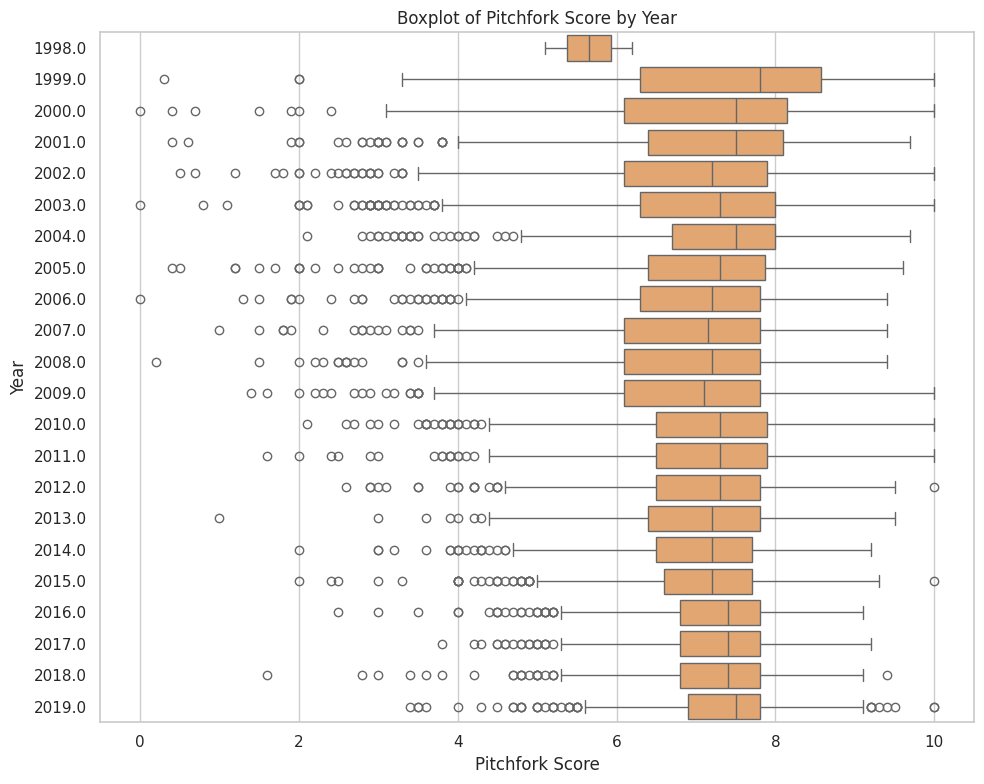

In [205]:
plt.figure(figsize=(10, 8))
sns.boxplot(
    data = pitchfork_df,
    x = 'score',
    y = 'releaseyear',
    order = year_summary.index,
    color = 'sandybrown',
    orient ='h'
)
plt.title('Boxplot of Pitchfork Score by Year')
plt.xlabel('Pitchfork Score')
plt.ylabel('Year')
plt.tight_layout()
plt.show()

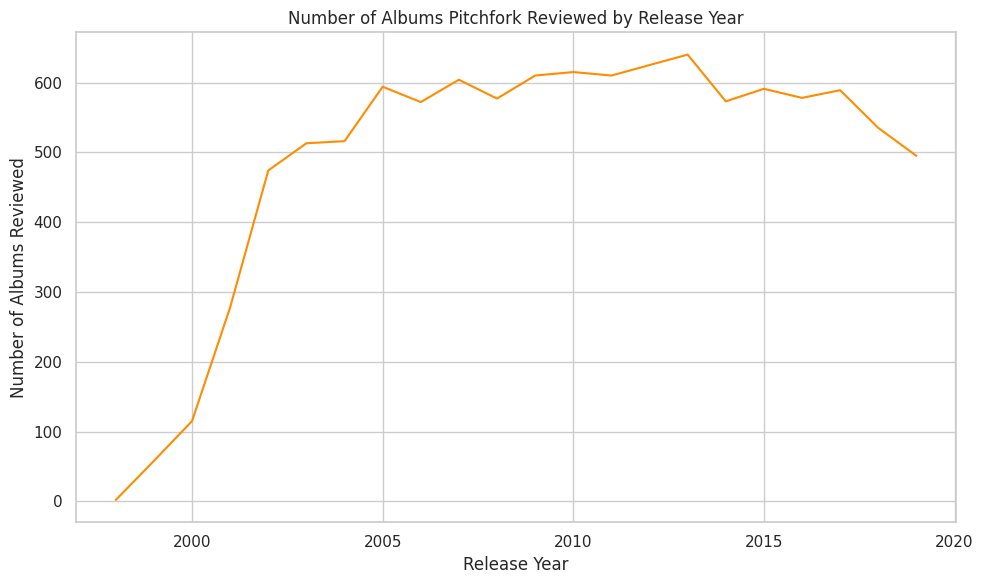

In [206]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data = year_summary,
    x = 'releaseyear',
    y = 'count',
    color = 'darkorange'
)
plt.title('Number of Albums Pitchfork Reviewed by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Albums Reviewed')

plt.tight_layout()
plt.show()